# 制定并执行清洗规则

In [1]:
# 导包
import pandas as pd
from config.config import REPORT_DIR,RAW_DATA_FILE
from src.data_loader import load_data

### 读取数据质量分析报告


In [2]:
report_path = REPORT_DIR/'data_quality_report.csv'
quality_report = load_data(report_path)
print(quality_report)

csv数据读取成功！
数据规模：6行 4列
   检查项目                    检查方法               问题描述             处理建议
0  字段缺失                isnull()          部分字段存在缺失值  根据字段业务含义决定删除或填充
1  重复记录            duplicated()     发现 34335 条重复记录   确认重复原因后再决定是否删除
2  负数数量            Quantity < 0    发现 22950 条负数量记录     结合取消订单业务规则判断
3   零数量           Quantity == 0        发现 0 条零数量记录       检查是否属于无效交易
4  异常单价  Price < 0 或 Price == 0    发现 6207 条非正单价记录     检查赠品、退款或异常交易
5  取消订单          Invoice 以 C 开头  发现 19494 条 C 开头记录  验证本地数据是否适用该识别规则


# 数据清洗计划（Data Cleaning Plan）

## 一、清洗目标

本阶段主要对 Online Retail II 原始数据集进行清洗和预处理，解决数据中存在的缺失值、重复记录、异常数据和数据格式不统一等问题，为后续的数据分析和可视化提供可靠的数据基础。

具体目标：

1. 统一字段名称和数据类型，提高数据规范性。
2. 检查并合理处理缺失值，减少无效数据对分析结果的影响。
3. 检查重复记录，避免重复数据影响统计结果。
4. 识别负数量、异常单价和取消订单等特殊业务数据。
5. 根据不同分析需求构建清洗后的数据集。
6. 保存清洗结果，为后续数据分析提供数据支持。

## 二、数据清洗原则

在清洗过程中遵循以下原则：

- **保留原始数据：** 不直接修改原始数据，所有清洗操作均在数据副本上进行。
- **结合业务含义：** 不盲目删除异常数据，需要结合零售交易业务判断数据是否有效。
- **保证可追溯性：** 对重要的数据清洗操作进行记录，方便后续检查和复现。
- **区分分析口径：** 根据不同分析需求构建不同的数据集，避免退货和取消订单影响正常销售统计。

## 三、具体清洗步骤

### 1. 数据格式标准化

主要任务：

- 统一字段名称，去除字段名称前后的空格。
- 将 InvoiceDate 转换为日期时间类型。
- 将 Quantity、Price 和 Customer ID 转换为数值类型。
- 清理 Invoice、StockCode、Description 和 Country 等字符串字段中的多余空格。
- 检查各字段的数据类型是否符合预期。

预期结果：数据字段名称统一，数据类型规范，便于后续处理。

### 2. 缺失值处理

主要任务：

- 使用 `isnull()` 检查各字段的缺失情况。
- 统计每个字段的缺失数量和缺失比例。
- 分析不同字段缺失值的业务含义。
- 根据字段特点决定保留、删除或填充。

处理原则：

- Customer ID 缺失：可以保留记录，但不参与需要客户身份的分析。
- Description 缺失：根据 StockCode 判断是否可以补充，无法确认时保留缺失或在特定分析中排除。
- Invoice、InvoiceDate 等关键字段缺失：根据实际情况判断是否属于无效交易。
- Quantity 和 Price 缺失：优先核查，不随意使用 0 填充。

### 3. 重复值处理

主要任务：

- 使用 `duplicated()` 检查完全重复记录。
- 统计重复记录的数量。
- 分析重复记录产生的原因。
- 检查跨工作表数据是否存在重复。
- 确认属于无效重复记录后再进行删除。

注意事项：

不能仅根据 Invoice 和 StockCode 判断记录是否重复，因为同一订单可能包含相同商品的多条交易记录。

预期结果：识别并处理确认无效的重复记录，避免重复统计。

### 4. 业务异常数据处理

主要任务：

- 检查 Quantity 小于 0 的记录。
- 检查 Price 小于或等于 0 的记录。
- 识别 Invoice 以 C 开头的记录。
- 检查极端交易数量和单价。
- 根据业务规则对特殊记录进行分类和标记。

处理原则：

- **负数量记录：** 可能代表退货或冲销，不直接删除。
- **零单价记录：** 可能代表赠品或特殊交易，需要进一步核查。
- **负单价记录：** 需要单独检查，判断是否属于退款或异常数据。
- **取消订单：** 对 Invoice 以 C 开头的记录进行标记，并结合实际数据验证识别规则。
- **极端值：** 可以使用 IQR（四分位距）方法识别，但不直接删除。

### 5. 构建分析数据集

根据不同的数据分析需求，构建两个数据集。

**（1）清洗后的完整数据集 cleaned_data**

保留具有分析价值的交易记录，包括：

- 正常销售记录
- 退货记录
- 取消订单记录
- 其他具有业务意义的特殊交易记录

主要用于数据质量分析、退货分析和订单行为分析。

**（2）销售分析数据集 sales_data**

从清洗后的数据中筛选符合正常销售统计口径的记录：

- Quantity > 0
- Price > 0
- InvoiceDate 有效

新增销售额字段：

`Sales = Quantity × Price`

主要用于销售额分析、商品销量分析、客户消费分析和国家销售情况分析。

注意：销售分析数据集的筛选条件应根据具体业务分析需求进一步调整。

### 6. 数据质量复检

主要任务：

- 再次检查缺失值。
- 再次检查完全重复记录。
- 检查数值字段是否存在无法转换的数据。
- 检查销售分析数据集是否存在非正数量或非正单价。
- 检查新增 Sales 字段是否存在异常值。
- 对比清洗前后的数据规模。

预期结果：确保清洗后的数据满足后续分析要求。

### 7. 保存清洗结果

将清洗后的数据保存到项目的 `data/processed/` 目录下。

计划输出文件：

| 文件名称 | 文件说明 |
|---|---|
| cleaned_data.csv | 清洗后的完整数据集 |
| sales_data.csv | 用于正常销售分析的数据集 |
| cleaning_report.csv | 数据清洗过程及质量检查报告 |

## 四、预期成果

完成本阶段后，预期得到以下成果：

1. 一份格式规范、具有可追溯性的完整清洗数据集。
2. 一份符合正常销售统计口径的销售分析数据集。
3. 一份记录数据清洗过程和处理结果的质量报告。
4. 为后续销售趋势分析、商品分析、客户分析和可视化工作提供可靠的数据基础。

## 五、清洗流程

原始数据加载
↓
数据格式标准化
↓
缺失值检查与处理
↓
重复值检查与处理
↓
业务异常数据识别与处理
↓
构建分析数据集
↓
数据质量复检
↓
保存清洗结果

---

**本阶段总结：**

数据清洗不仅是删除错误数据，更重要的是结合实际业务理解数据。对于退货、取消订单和特殊价格等记录，应尽可能保留其业务信息，并根据不同的分析目标选择合适的数据口径。

### 加载原数据

In [3]:
df = load_data(RAW_DATA_FILE)
# 备份原始数据
df_raw = df.copy()

print("数据读取成功！")
print("原始数据规模：", df.shape)

csv数据读取成功！
数据规模：1067371行 8列
数据读取成功！
原始数据规模： (1067371, 8)


### 数据格式标准化

In [4]:
# df.info()
# 去除字段前后的空格
df.columns = df.columns.str.strip()
print(df.columns.tolist())

# 需要处理的字符串类型字段
string_columns = ['Invoice','StockCode','Description','Country']
for col in string_columns:
    if col in df.columns:
        df[col] = df[col].astype('string').str.strip()


# 转换日期字段
df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'],
    errors='coerce'
)

# 转换数值字段

numeric_columns = ['Quantity', 'Price', 'Customer ID']
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("数据类型转换完成！")
df.info()

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
数据类型转换完成！
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  string        
 1   StockCode    1067371 non-null  string        
 2   Description  1062989 non-null  string        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  string        
dtypes: datetime64[us](1), float64(2), int64(1), string(4)
memory usage: 117.5 MB


### 2. 缺失值检查与处理

本阶段主要检查数据集中各字段的缺失情况，统计缺失数量和缺失比例，并结合零售交易业务含义制定处理策略。

具体任务：
1. 检查各字段的缺失数量。
2. 计算各字段的缺失比例。
3. 分析缺失值产生的原因。
4. 根据字段业务含义制定处理方案。

In [7]:
# 统计每个字段的缺失数量
missing_count = df.isnull().sum()

# 计算每个字段的缺失比例
missing_rate = df.isnull().mean() * 100

# 整理缺失值统计结果
missing_report = pd.DataFrame({
    '缺失数量': missing_count,
    '缺失比例(%)': missing_rate.round(2)
})

# 按缺失数量降序排列
missing_report = missing_report.sort_values(
    by='缺失数量',
    ascending=False
)

display(missing_report)
print(missing_report)

,缺失数量,缺失比例(%)
Customer ID,243007,22.77
Description,4382,0.41
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


               缺失数量  缺失比例(%)
Customer ID  243007    22.77
Description    4382     0.41
StockCode         0     0.00
Invoice           0     0.00
Quantity          0     0.00
InvoiceDate       0     0.00
Price             0     0.00
Country           0     0.00


C:\Users\30372\AppData\Local\Temp\ipykernel_18316\954812199.py:20: UserWarning: Glyph 23383 (\N{CJK UNIFIED IDEOGRAPH-5B57}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\30372\AppData\Local\Temp\ipykernel_18316\954812199.py:20: UserWarning: Glyph 27573 (\N{CJK UNIFIED IDEOGRAPH-6BB5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\30372\AppData\Local\Temp\ipykernel_18316\954812199.py:20: UserWarning: Glyph 21517 (\N{CJK UNIFIED IDEOGRAPH-540D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\30372\AppData\Local\Temp\ipykernel_18316\954812199.py:20: UserWarning: Glyph 31216 (\N{CJK UNIFIED IDEOGRAPH-79F0}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\30372\AppData\Local\Temp\ipykernel_18316\954812199.py:20: UserWarning: Glyph 32570 (\N{CJK UNIFIED IDEOGRAPH-7F3A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\30372\AppData\Local\Temp\ipykernel_18316\954812199.py:20: UserWarning: Glyph 22833 (\N{CJK 

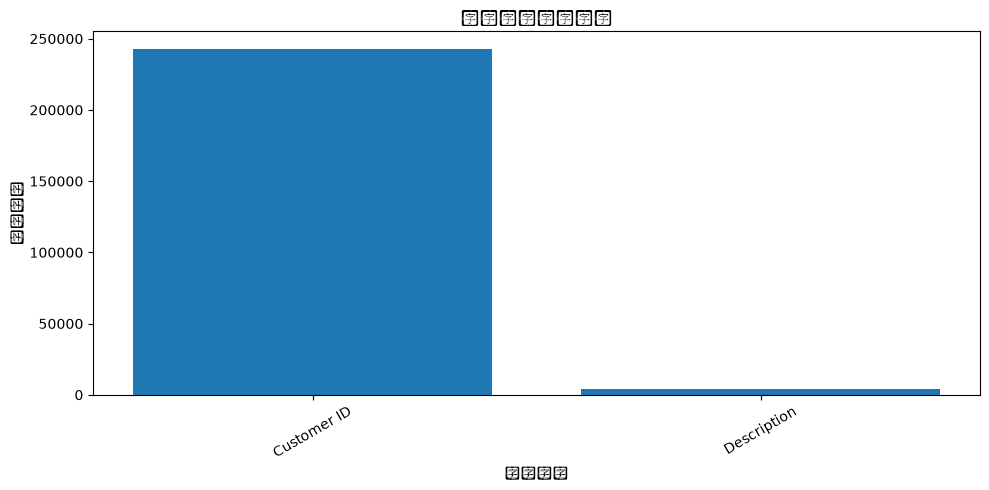

In [6]:
import matplotlib.pyplot as plt

# 筛选存在缺失值的字段
missing_data = missing_report[
    missing_report['缺失数量'] > 0
]

plt.figure(figsize=(10, 5))

plt.bar(
    missing_data.index,
    missing_data['缺失数量']
)

plt.title('各字段缺失值数量')
plt.xlabel('字段名称')
plt.ylabel('缺失数量')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### 2.1 商品描述缺失值处理

针对 Description 字段中的缺失记录，尝试利用 StockCode 查找其他交易记录中对应的商品描述。

处理步骤：
1. 筛选 Description 缺失的记录。
2. 根据 StockCode 查找其他记录中的商品描述。
3. 检查同一个 StockCode 是否对应多个不同描述。
4. 对描述唯一且可靠的商品编码进行补充。
5. 对无法确定描述的记录保留缺失值。

In [11]:
# 筛选商品描述缺失的记录
missing_description = df[df['Description'].isna()].copy()
print("商品描述缺失记录数：", len(missing_description))

# 统计每个 StockCode 对应的不同商品描述数量
description_count = (
    df.dropna(subset=['Description'])
      .groupby('StockCode')['Description']
      .nunique()
)
# print(description_count)
# 找出只有一种商品描述的 StockCode
unique_description_codes = description_count[
    description_count == 1
].index
# print(unique_description_codes)
# 统计可以尝试补充的记录
can_fill = missing_description[
    missing_description['StockCode'].isin(unique_description_codes)
]
# 统计无法确定商品描述的记录
cannot_fill = missing_description[
    ~missing_description['StockCode'].isin(unique_description_codes)
]
print("可以尝试补充的记录数：", len(can_fill))
print("暂时无法确定描述的记录数：", len(cannot_fill))

# 查看部分缺失记录
display(missing_description.head(10))

商品描述缺失记录数： 4382
可以尝试补充的记录数： 3072
暂时无法确定描述的记录数： 1310


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,<NA>,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,<NA>,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,<NA>,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,<NA>,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4566,489821,85049G,<NA>,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom
6378,489882,35751C,<NA>,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom
6555,489898,79323G,<NA>,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom
6576,489901,21098,<NA>,-200,2009-12-03 09:47:00,0.0,NaN,United Kingdom
6581,489903,21166,<NA>,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom


In [12]:
# 提取商品编码和对应的商品描述
description_map = (
    df.dropna(subset=['Description'])
      .drop_duplicates(subset=['StockCode', 'Description'])
      .groupby('StockCode')['Description']
      .first()
)

# 只保留描述唯一的商品编码
description_map = description_map[
    description_map.index.isin(unique_description_codes)
]

print("可用于补充的商品编码数量：", len(description_map))

display(description_map.head(10))

可用于补充的商品编码数量： 3735


StockCode
10002       INFLATABLE POLITICAL GLOBE
10002R           ROBOT PENCIL SHARPNER
10109             BENDY COLOUR PENCILS
10123C            HEARTS WRAPPING TAPE
10123G         ARMY CAMO WRAPPING TAPE
10124A     SPOTS ON RED BOOKCOVER TAPE
10124G        ARMY CAMO BOOKCOVER TAPE
10125          MINI FUNKY DESIGN TAPES
10134     COLOURING PENCILS BROWN TUBE
10135     COLOURING PENCILS BROWN TUBE
Name: Description, dtype: string

In [13]:
# 记录补充前的缺失数量
before_missing = df['Description'].isna().sum()

# 根据 StockCode 查找对应的 Description
df['Description'] = df['Description'].fillna(
    df['StockCode'].map(description_map)
)

# 记录补充后的缺失数量
after_missing = df['Description'].isna().sum()

print("补充前缺失数量：", before_missing)
print("补充后缺失数量：", after_missing)
print("成功补充数量：", before_missing - after_missing)

补充前缺失数量： 4382
补充后缺失数量： 1310
成功补充数量： 3072


In [14]:
# 查看补充后的前10条记录
display(
    df.loc[
        missing_description.index,
        ['StockCode', 'Description', 'Quantity', 'Price']
    ].head(10)
)

,StockCode,Description,Quantity,Price
470,21646,<NA>,-50,0.0
3114,20683,RAIN GIRL CHILDS UMBRELLA,-44,0.0
3161,21350,GINGHAM HEART WREATH,230,0.0
3731,84292,ROSE PINK METAL FOLDING CHAIR,17,0.0
4296,18010,ASSORTED FRAGRANCE BATH CONFETTI,-770,0.0
4566,85049G,CHOCOLATE BOX RIBBONS,-240,0.0
6378,35751C,PURPLE CURRENT CANDLE RING,12,0.0
6555,79323G,<NA>,954,0.0
6576,21098,<NA>,-200,0.0
6581,21166,<NA>,48,0.0


In [15]:
# 将 Customer ID 转换为可空整数类型
df['Customer ID'] = df['Customer ID'].astype('Int64')

print("Customer ID 数据类型：", df['Customer ID'].dtype)
print("Customer ID 缺失数量：", df['Customer ID'].isna().sum())
# 统计当前所有字段的缺失情况
missing_report = pd.DataFrame({
    '缺失数量': df.isnull().sum(),
    '缺失比例(%)': (df.isnull().mean() * 100).round(2)
})

display(missing_report)

Customer ID 数据类型： Int64
Customer ID 缺失数量： 243007


,缺失数量,缺失比例(%)
Invoice,0,0.00
StockCode,0,0.00
Description,1310,0.12
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


### 2.2 Customer ID 缺失值处理

Customer ID 字段存在大量缺失记录。

由于客户编号缺失并不代表交易记录无效，
因此本项目不删除这些记录，也不对缺失的客户编号进行填充。

处理措施：
1. 保留 Customer ID 缺失的交易记录。
2. 将 Customer ID 转换为 pandas 可空整数类型 Int64。
3. 在客户分析时排除客户编号缺失的记录。
4. 在销售分析时，根据具体业务口径决定是否保留。

本阶段完成了 Description 和 Customer ID 两个字段的缺失值处理。